# RT-IoT2022 — Intrusion detection on IoT network traffic
## Deliverable 1 — Data loading and first exploration

**Group members (same order as in the file name):**

| # | Last name | First name |
|---|-----------|------------|
| 1 | Ben Abderrazak | Mohamed Rached |
| 2 | Hasnaoui | Yasmine |
| 3 | Smaili | Ahmed |
| 4 | Zammouri | Mohamed Chrif |

**Course:** Artificial Intelligence — Instructor: Faouzi MOUSSA

## 0. Project context

- **Problem:** detect malicious traffic in an IoT network. Each row is one *network flow* (a connection between two devices) described by statistics about its packets.
- **Goal:** predict whether a flow is **benign** or an **attack** (binary target `label`), and, as a second step, identify **which type of attack** it is (multi-class target `Attack_type`).
- **Data source:** *RT-IoT2022*, UCI Machine Learning Repository — <https://archive.ics.uci.edu/dataset/942/rt-iot2022> (UCI id = 942). It mixes normal IoT device traffic (MQTT, ThingSpeak, Wipro smart bulb) with simulated attacks (DoS/DDoS, ARP poisoning, Nmap scans, SSH brute force).
- **Observations:** 123,117 flows (checked below).
- **Scope of this notebook:** load the data, show its size and some examples, and explain the main columns. No model is trained here.

## 1. Setup

In [2]:
from pathlib import Path
import fnmatch

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
DATA_PATH     = Path("../Data/raw/dataset.csv")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 200)
pd.set_option("display.precision", 6)

RANDOM_STATE = 42

In [3]:
# Download raw dataset
#======EXECUTE THIS CELL ONLY ONCE======
# %pip install -q datasets pandas pyarrow numpy scipy matplotlib seaborn scikit-learn statsmodels

# from pathlib import Path
# import urllib.request

# DATA_DIR = Path("../Data/raw")
# DATA_DIR.mkdir(parents=True, exist_ok=True)

# url = "https://huggingface.co/datasets/michaelmallari/rt-iot2022/resolve/main/rt-iot2022.csv"

# urllib.request.urlretrieve(url, DATA_DIR / "dataset.csv")

# print("Setup completed!")

## 2. Loading the data

The notebook looks for the file `data/raw/dataset.csv` **next to the notebook** (relative path, so it works on any machine).

- If the file is there (it is attached to our submission), it is simply read.
- If it is missing, it is downloaded automatically from the UCI repository with the `ucimlrepo` package (internet needed; `pip install ucimlrepo`), then saved to that path.

**Binary label:** `label = 0` (benign) for the normal-traffic classes (MQTT, ThingSpeak, Wipro bulb, Alexa) and `label = 1` (attack) for every other class. This column is **created by us** from `Attack_type`; it is not in the original data.

In [4]:
df = pd.read_csv(DATA_PATH)

NORMAL_KEYS = ("mqtt", "thing", "wipro", "alexa")

is_normal = df["Attack_type"].str.lower().str.contains("|".join(NORMAL_KEYS))
df["label"] = (~is_normal).astype(int)

TARGETS = ["Attack_type", "label"]

print(df["label"].value_counts())

label
1    110610
0     12507
Name: count, dtype: int64


## 3. Size of the dataset

In [5]:
n_rows, n_cols = df.shape
print(f"Rows (observations): {n_rows:,}")
print(f"Columns            : {n_cols}")
print(f"  -> targets       : {len(TARGETS)} {TARGETS}")
print(f"  -> input features: {n_cols - len(TARGETS)}")

Rows (observations): 123,117
Columns            : 86
  -> targets       : 2 ['Attack_type', 'label']
  -> input features: 84


## 4. First look at the data

### 4.1 First 5 rows (as rows)

In [6]:
df.head(5)

,Unnamed: 0,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,bwd_pkts_tot,fwd_data_pkts_tot,bwd_data_pkts_tot,fwd_pkts_per_sec,bwd_pkts_per_sec,flow_pkts_per_sec,down_up_ratio,fwd_header_size_tot,fwd_header_size_min,fwd_header_size_max,bwd_header_size_tot,bwd_header_size_min,bwd_header_size_max,flow_FIN_flag_count,flow_SYN_flag_count,flow_RST_flag_count,fwd_PSH_flag_count,bwd_PSH_flag_count,flow_ACK_flag_count,fwd_URG_flag_count,bwd_URG_flag_count,flow_CWR_flag_count,flow_ECE_flag_count,fwd_pkts_payload.min,fwd_pkts_payload.max,fwd_pkts_payload.tot,fwd_pkts_payload.avg,fwd_pkts_payload.std,bwd_pkts_payload.min,bwd_pkts_payload.max,bwd_pkts_payload.tot,bwd_pkts_payload.avg,bwd_pkts_payload.std,flow_pkts_payload.min,flow_pkts_payload.max,flow_pkts_payload.tot,flow_pkts_payload.avg,flow_pkts_payload.std,fwd_iat.min,fwd_iat.max,fwd_iat.tot,fwd_iat.avg,fwd_iat.std,bwd_iat.min,bwd_iat.max,bwd_iat.tot,bwd_iat.avg,bwd_iat.std,flow_iat.min,flow_iat.max,flow_iat.tot,flow_iat.avg,flow_iat.std,payload_bytes_per_second,fwd_subflow_pkts,bwd_subflow_pkts,fwd_subflow_bytes,bwd_subflow_bytes,fwd_bulk_bytes,bwd_bulk_bytes,fwd_bulk_packets,bwd_bulk_packets,fwd_bulk_rate,bwd_bulk_rate,active.min,active.max,active.tot,active.avg,active.std,idle.min,idle.max,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type,label
0,0,38667,1883,tcp,mqtt,32.011598,9,5,3,3,0.281148,0.156193,0.437341,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,76.0,8.444444,13.115936,0.0,23.0,32.0,6.4,9.555103,0.0,33.0,108.0,7.714286,11.618477,761.985779,2.972918e+07,3.201160e+07,4.001450e+06,1.040307e+07,4438.877106,1.511694e+06,2.026391e+06,506597.757339,680406.147126,761.985779,2.972918e+07,3.201160e+07,2.462431e+06,8.199747e+06,3.373777,3.0,1.666667,25.333333,10.666667,0.0,0.0,0.0,0.0,0.0,0.0,2.282415e+06,2.282415e+06,2.282415e+06,2.282415e+06,0.0,2.972918e+07,2.972918e+07,2.972918e+07,2.972918e+07,0.0,64240,26847,502,MQTT_Publish,0
1,1,51143,1883,tcp,mqtt,31.883584,9,5,3,3,0.282277,0.156821,0.439097,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,76.0,8.444444,13.115936,0.0,23.0,32.0,6.4,9.555103,0.0,33.0,108.0,7.714286,11.618477,247.001648,2.985528e+07,3.188358e+07,3.985448e+06,1.046346e+07,4214.048386,1.576436e+06,1.876261e+06,469065.248966,741351.686212,247.001648,2.985528e+07,3.188358e+07,2.452583e+06,8.242459e+06,3.387323,3.0,1.666667,25.333333,10.666667,0.0,0.0,0.0,0.0,0.0,0.0,2.028307e+06,2.028307e+06,2.028307e+06,2.028307e+06,0.0,2.985528e+07,2.985528e+07,2.985528e+07,2.985528e+07,0.0,64240,26847,502,MQTT_Publish,0
2,2,44761,1883,tcp,mqtt,32.124053,9,5,3,3,0.280164,0.155647,0.435811,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,74.0,8.222222,12.852799,0.0,21.0,30.0,6.0,8.689074,0.0,33.0,104.0,7.428571,11.229866,283.956528,2.984215e+07,3.212405e+07,4.015507e+06,1.044238e+07,2456.903458,1.476049e+06,2.013770e+06,503442.466259,660344.360027,283.956528,2.984215e+07,3.212405e+07,2.471081e+06,8.230593e+06,3.237450,3.0,1.666667,24.666667,10.000000,0.0,0.0,0.0,0.0,0.0,0.0,2.281904e+06,2.281904e+06,2.281904e+06,2.281904e+06,0.0,2.984215e+07,2.984215e+07,2.984215e+07,2.984215e+07,0.0,64240,26847,502,MQTT_Publish,0
3,3,60893,1883,tcp,mqtt,31.961063,9,5,3,3,0.281593,0.156440,0.438033,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,74.0,8.222222,12.852799,0.0,21.0,30.0,6.0,8.689074,0.0,33.0,104.0,7.428571,11.229866,288.963318,2.991377e+07,3.196106e+07,3.995133e+06,1.048253e+07,3933.906555,1.551892e+06,1.883784e+06,470946.013927,724569.317911,288.963318,2.991377e+07,3.196106e+07,2.458543e+06,8.257786e+06,3.253959,3.0,1.666667,24.666667,10.000000,0.0,0.0,0.0,0.0,0.0,0.0,2.047288e+06,2.047288e+06,2.047288e+06,2.047288e+06,0.0,2.991377e+07,2.991377e+07,2.991377e+07,2.991377e+07,0.0,64240,26847,502,MQTT_Publish,0
4,4,51087,1883,tcp,mqtt,31.902362,9,5,3,3,0.282111,0.156728,0.438839,0.555556,296,32,40,168,32,40,0,2,1,3,3,13,0,0,0,0,0.0,33.0,76.0,8.444444,13.115936,0.0,23.0,32.0,6

### 4.2 One flow read line by line

The table is 85 columns wide, so here the **first flow** (row 0) is shown vertically: one line per column, with its value.

In [7]:

df.iloc[0].to_frame("row 0").rename_axis("column")


,row 0
column,
Unnamed: 0,0
id.orig_p,38667
id.resp_p,1883
proto,tcp
service,mqtt
flow_duration,32.011598
fwd_pkts_tot,9
bwd_pkts_tot,5
fwd_data_pkts_tot,3


### 4.3 One fixed example per class

For each of the 12 classes we take its **first occurrence** in the file (always the same rows, no randomness), so every type of traffic is shown once.

In [8]:
first_rows = df.groupby("Attack_type").head(1).sort_values("Attack_type")
cols_show = ["Attack_type", "label", "proto", "service", "id.resp_p",
             "flow_duration", "fwd_pkts_tot", "bwd_pkts_tot", "flow_SYN_flag_count"]
cols_show = [c for c in cols_show if c in df.columns]

first_rows[cols_show]   # the index shows the row number of each example in the file


,Attack_type,label,proto,service,id.resp_p,flow_duration,fwd_pkts_tot,bwd_pkts_tot,flow_SYN_flag_count
12507,ARP_poisioning,1,udp,dns,5353,0.000000,1,0,0
20257,DDOS_Slowloris,1,tcp,http,80,0.000181,8,0,2
20791,DOS_SYN_Hping,1,tcp,-,21,0.000041,1,1,1
0,MQTT_Publish,0,tcp,mqtt,1883,32.011598,9,5,2
115450,Metasploit_Brute_Force_SSH,1,udp,dns,53,0.000856,2,2,0
115487,NMAP_FIN_SCAN,1,tcp,http,80,0.575884,6,5,2
115515,NMAP_OS_DETECTION,1,tcp,-,1723,0.000034,1,1,0
117515,NMAP_TCP_scan,1,tcp,-,8888,0.000199,3,0,0
118517,NMAP_UDP_SCAN,1,tcp,http,80,0.000261,8,0,2
121107,NMAP_XMAS_TREE_SCAN,1,tcp,http,80,2.260214,7,5,3


## 5. Structure of the dataset (`info`, types, missing values)

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 123117 entries, 0 to 123116
Data columns (total 86 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Unnamed: 0                123117 non-null  int64  
 1   id.orig_p                 123117 non-null  int64  
 2   id.resp_p                 123117 non-null  int64  
 3   proto                     123117 non-null  str    
 4   service                   123117 non-null  str    
 5   flow_duration             123117 non-null  float64
 6   fwd_pkts_tot              123117 non-null  int64  
 7   bwd_pkts_tot              123117 non-null  int64  
 8   fwd_data_pkts_tot         123117 non-null  int64  
 9   bwd_data_pkts_tot         123117 non-null  int64  
 10  fwd_pkts_per_sec          123117 non-null  float64
 11  bwd_pkts_per_sec          123117 non-null  float64
 12  flow_pkts_per_sec         123117 non-null  float64
 13  down_up_ratio             123117 non-null  float64
 14 

In [10]:
is_int   = df.dtypes.apply(pd.api.types.is_integer_dtype)
is_float = df.dtypes.apply(pd.api.types.is_float_dtype)
is_text  = ~(is_int | is_float)

display(pd.DataFrame({
    "Type": ["int", "float", "text (categorical)", "TOTAL"],
    "Columns": [is_int.sum(), is_float.sum(), is_text.sum(), n_cols],
}))
print("Text columns       :", list(df.columns[is_text]))
print("Missing values     :", int(df.isna().sum().sum()))
print("Duplicated rows    :", int(df.duplicated().sum()))

,Type,Columns
0,int,27
1,float,56
2,text (categorical),3
3,TOTAL,86


Text columns       : ['proto', 'service', 'Attack_type']
Missing values     : 0
Duplicated rows    : 0


### 5.1 Missing values

In [11]:

missing = df.isna().sum()
n_inf = np.isinf(df.select_dtypes("number")).sum().sum()   # infinite values also count as "unusable"

print(f"Total missing values            : {int(missing.sum()):,} "
      f"({missing.sum() / df.size:.4%} of the {df.size:,} cells)")
print(f"Columns with a missing value    : {int((missing > 0).sum())} / {df.shape[1]}")
print(f"Rows with a missing value       : {int(df.isna().any(axis=1).sum()):,}")
print(f"Infinite values (numeric cols)  : {int(n_inf):,}")

missing_table = (pd.DataFrame({"missing": missing,
                               "percent": (missing / len(df) * 100).round(4)})
                   .query("missing > 0")
                   .sort_values("missing", ascending=False))
if missing_table.empty:
    print("\n-> No missing value in any column.")
else:
    display(missing_table)


Total missing values            : 0 (0.0000% of the 10,588,062 cells)
Columns with a missing value    : 0 / 86
Rows with a missing value       : 0
Infinite values (numeric cols)  : 0

-> No missing value in any column.


### 5.2 Outliers (IQR method)

A value is flagged as an **outlier** when it lies outside `[Q1 − 1.5·IQR , Q3 + 1.5·IQR]`, where IQR = Q3 − Q1.
The port columns (`id.orig_p`, `id.resp_p`) and the target `label` are excluded: ports are identifiers, not quantities.

In [12]:

num = df.select_dtypes("number").drop(columns=["label", "id.orig_p", "id.resp_p"], errors="ignore")

q1, q3 = num.quantile(0.25), num.quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
is_out = num.lt(lower) | num.gt(upper)          # True where the value is an outlier

outliers = pd.DataFrame({
    "Q1": q1, "Q3": q3, "IQR": iqr,
    "lower_bound": lower, "upper_bound": upper,
    "n_outliers": is_out.sum(),
    "percent": (is_out.mean() * 100).round(2),
    "min": num.min(), "max": num.max(),
}).sort_values("percent", ascending=False)

print(f"Numeric columns analysed                 : {num.shape[1]}")
print(f"Columns with at least one outlier        : {int((outliers.n_outliers > 0).sum())}")
print(f"Columns with IQR = 0 (flag = any change) : {int((outliers.IQR == 0).sum())}")
print(f"Rows with at least one outlier           : {int(is_out.any(axis=1).sum()):,} "
      f"({is_out.any(axis=1).mean():.2%})")
print(f"Share of all numeric cells that are outliers: {is_out.to_numpy().mean():.2%}")

print("\nTop 20 columns by % of outliers:")
display(outliers.head(20))


Numeric columns analysed                 : 80
Columns with at least one outlier        : 74
Columns with IQR = 0 (flag = any change) : 65
Rows with at least one outlier           : 38,295 (31.10%)
Share of all numeric cells that are outliers: 12.90%

Top 20 columns by % of outliers:


,Q1,Q3,IQR,lower_bound,upper_bound,n_outliers,percent,min,max
flow_pkts_payload.avg,60.0,60.0,0.0,60.0,60.0,38116,30.96,0.0,1.156085e+03
bwd_header_size_tot,20.0,20.0,0.0,20.0,20.0,33148,26.92,0.0,3.235920e+05
bwd_header_size_max,20.0,20.0,0.0,20.0,20.0,33137,26.92,0.0,4.400000e+01
flow_ACK_flag_count,1.0,1.0,0.0,1.0,1.0,33083,26.87,0.0,1.177200e+04
bwd_pkts_tot,1.0,1.0,0.0,1.0,1.0,32364,26.29,0.0,1.011200e+04
bwd_subflow_pkts,1.0,1.0,0.0,1.0,1.0,32343,26.27,0.0,1.685333e+03
bwd_header_size_min,20.0,20.0,0.0,20.0,20.0,32065,26.04,0.0,4.000000e+01
fwd_pkts_payload.min,120.0,120.0,0.0,120.0,120.0,28458,23.11,0.0,1.097000e+03
fwd_pkts_payload.avg,120.0,120.0,0.0,120.0,120.0,28458,23.11,0.0,1.319365e+03
flow_pkts_payload.tot,120.0,120.0,0.0,120.0,120.0,28455,23.11,0.0,1.361058e+07


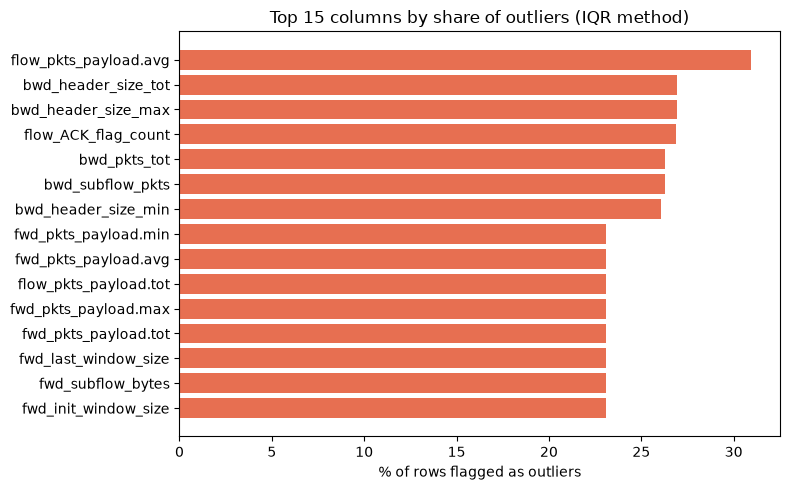

In [13]:

top = outliers.head(15).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top.index, top["percent"], color="#e76f51")
plt.xlabel("% of rows flagged as outliers")
plt.title("Top 15 columns by share of outliers (IQR method)")
plt.tight_layout()
plt.show()



**How to read this:** the distributions are very skewed (most flows are tiny, a few are huge), so the IQR rule flags **many** values. Here, extreme values are often **real attack traffic** (floods, scans) and not measurement errors, so we will **not delete outliers blindly**. For V1 we plan to keep them and handle the skew with tree-based models or a log transform. Columns with IQR = 0 are almost constant, so any different value is flagged; they are candidates for removal in the feature selection step.


## 6. Meaning of the main columns

Each row is one **flow** (a connection between an *originator* and a *responder*). Naming convention in the column names:

- `fwd_` = **forward** direction (originator → responder); `bwd_` = **backward** direction (responder → originator); `flow_` = both directions together.
- `pkts` = packets; `iat` = **inter-arrival time** (time between two consecutive packets); `.min / .max / .avg / .std / .tot` = minimum / maximum / mean / standard deviation / total of that quantity over the flow.

The table below is generated from the real column names, so we can check that every column is documented.

In [14]:
# (group, patterns matching column names, meaning) — first matching group wins
COLUMN_GROUPS = [
    ("Ports",            ["id.orig_p", "id.resp_p"],
     "Source port (originator) and destination port (responder). The destination port reveals the service, e.g. 1883 = MQTT, 21 = FTP."),
    ("Protocol / service", ["proto", "service"],
     "Transport protocol (tcp, udp, icmp) and detected application service ('-' = service not identified). Categorical."),
    ("Duration",         ["flow_duration"],
     "Duration of the flow in seconds."),
    ("Packet counts",    ["fwd_pkts_tot", "bwd_pkts_tot", "fwd_data_pkts_tot", "bwd_data_pkts_tot"],
     "Number of packets sent in each direction (total, and only those carrying data)."),
    ("Rates and ratios", ["fwd_pkts_per_sec", "bwd_pkts_per_sec", "flow_pkts_per_sec", "down_up_ratio", "payload_bytes_per_second"],
     "Packets per second (forward / backward / both), ratio of backward to forward packets, and payload bytes per second."),
    ("Header sizes",     ["*_header_size_*"],
     "Total / min / max size of packet headers, per direction."),
    ("TCP flags",        ["*_flag_count"],
     "Number of packets with each TCP flag (SYN, FIN, RST, ACK, PSH, URG, CWR, ECE). Very informative for scans and SYN floods."),
    ("Payload sizes",    ["*pkts_payload.*"],
     "Statistics (min, max, mean, std, total) of packet payload size, per direction and for the whole flow."),
    ("Inter-arrival times", ["*_iat.*"],
     "Statistics of the time between consecutive packets (forward, backward, flow). Bots and floods have very regular, short gaps."),
    ("Subflows",         ["*_subflow_*"],
     "Average packets / bytes per subflow, per direction."),
    ("Bulk transfer",    ["*_bulk_*"],
     "Bytes, packets and rate of bulk (back-to-back) data transfers, per direction."),
    ("Active / idle",    ["active.*", "idle.*"],
     "Statistics of the periods during which the flow was active or idle."),
    ("TCP window",       ["*_window_size"],
     "TCP window size announced at the start (init) and end (last) of the flow."),
    ("TARGETS",          ["Attack_type", "label"],
     "Attack_type: name of the traffic class (12 classes). label: 0 = benign, 1 = attack (created by us)."),
]

rows, assigned = [], set()
for group, patterns, meaning in COLUMN_GROUPS:
    cols = [c for c in df.columns if c not in assigned and any(fnmatch.fnmatchcase(c, p) for p in patterns)]
    assigned.update(cols)
    if cols:
        rows.append({"Group": group, "N": len(cols), "Columns": ", ".join(cols), "Meaning": meaning})

col_doc = pd.DataFrame(rows)
with pd.option_context("display.max_colwidth", 110):
    display(col_doc[["Group", "N", "Meaning"]])

undocumented = [c for c in df.columns if c not in assigned]
print(f"Documented columns: {len(assigned)}/{n_cols}   |   not documented: {undocumented}")

,Group,N,Meaning
0,Ports,2,"Source port (originator) and destination port (responder). The destination port reveals the service, e.g. ..."
1,Protocol / service,2,"Transport protocol (tcp, udp, icmp) and detected application service ('-' = service not identified). Categ..."
2,Duration,1,Duration of the flow in seconds.
3,Packet counts,4,"Number of packets sent in each direction (total, and only those carrying data)."
4,Rates and ratios,5,"Packets per second (forward / backward / both), ratio of backward to forward packets, and payload bytes pe..."
5,Header sizes,6,"Total / min / max size of packet headers, per direction."
6,TCP flags,10,"Number of packets with each TCP flag (SYN, FIN, RST, ACK, PSH, URG, CWR, ECE). Very informative for scans ..."
7,Payload sizes,15,"Statistics (min, max, mean, std, total) of packet payload size, per direction and for the whole flow."
8,Inter-arrival times,15,"Statistics of the time between consecutive packets (forward, backward, flow). Bots and floods have very re..."
9,Subflows,4,"Average packets / bytes per subflow, per direction."


Documented columns: 85/86   |   not documented: ['Unnamed: 0']


## 7. Statistics of the main numeric columns

In [15]:
main_cols = ["flow_duration", "fwd_pkts_tot", "bwd_pkts_tot", "flow_pkts_per_sec",
             "flow_pkts_payload.tot", "flow_SYN_flag_count", "flow_ACK_flag_count", "flow_iat.avg"]
main_cols = [c for c in main_cols if c in df.columns]
df[main_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
flow_duration,123117.0,3.809566,130.005408,0.0,0.000001,0.000004,5.000000e-06,2.172834e+04
fwd_pkts_tot,123117.0,2.268826,22.336565,0.0,1.000000,1.000000,1.000000e+00,4.345000e+03
bwd_pkts_tot,123117.0,1.909509,33.018311,0.0,1.000000,1.000000,1.000000e+00,1.011200e+04
flow_pkts_per_sec,123117.0,703568.288005,741563.422208,0.0,149.087077,493447.529412,1.048576e+06,2.097152e+06
flow_pkts_payload.tot,123117.0,734.517199,42965.991708,0.0,120.000000,120.000000,1.200000e+02,1.361058e+07
flow_SYN_flag_count,123117.0,0.950868,0.474262,0.0,1.000000,1.000000,1.000000e+00,8.000000e+00
flow_ACK_flag_count,123117.0,2.677737,41.654868,0.0,1.000000,1.000000,1.000000e+00,1.177200e+04
flow_iat.avg,123117.0,139654.485986,874802.641519,0.0,0.953674,4.053116,5.006790e+00,7.283576e+07


**Reading:** for most of these columns the median is very small compared with the maximum (e.g. `flow_duration`), so the distributions are **extremely skewed**: most flows are tiny and a few are huge. This will matter for the preprocessing (scaling, log transform, or tree-based models that are insensitive to scale).

In [16]:
display(df.select_dtypes(exclude="number").describe().T)
for c in ["proto", "service"]:
    print(f"\n--- {c} ---")
    print(df[c].value_counts())

,count,unique,top,freq
proto,123117,3,tcp,110427
service,123117,10,-,102861
Attack_type,123117,12,DOS_SYN_Hping,94659



--- proto ---
proto
tcp     110427
udp      12633
icmp        57
Name: count, dtype: int64

--- service ---
service
-         102861
dns         9753
mqtt        4132
http        3464
ssl         2663
ntp          121
dhcp          50
irc           43
ssh           28
radius         2
Name: count, dtype: int64


## 8. Target variables

### 8.1 Binary target `label` (0 = benign, 1 = attack)

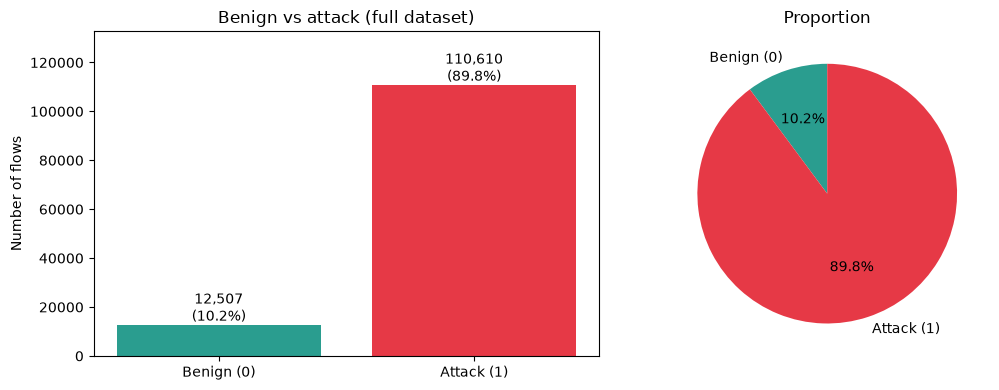

In [17]:
names = {0: "Benign (0)", 1: "Attack (1)"}
counts = df["label"].value_counts().sort_index()
total = counts.sum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
bars = ax1.bar([names[i] for i in counts.index], counts.values, color=["#2a9d8f", "#e63946"])
for b, v in zip(bars, counts.values):
    ax1.text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / total:.1%})", ha="center", va="bottom")
ax1.set_ylim(0, counts.max() * 1.2)
ax1.set_ylabel("Number of flows")
ax1.set_title("Benign vs attack (full dataset)")
ax2.pie(counts.values, labels=[names[i] for i in counts.index], autopct="%1.1f%%",
        colors=["#2a9d8f", "#e63946"], startangle=90)
ax2.set_title("Proportion")
plt.tight_layout()
plt.show()

**Observation:** the dataset is **strongly imbalanced** (about 90 % attacks). Accuracy alone would be misleading: a model that always answers "attack" would already score ~90 %. We will therefore also use precision, recall, F1-score and the confusion matrix, and a stratified train/test split.

### 8.2 Multi-class target `Attack_type`

,flows,percent,label
Attack_type,,,
DOS_SYN_Hping,94659,76.89,1
Thing_Speak,8108,6.59,0
ARP_poisioning,7750,6.29,1
MQTT_Publish,4146,3.37,0
NMAP_UDP_SCAN,2590,2.10,1
NMAP_XMAS_TREE_SCAN,2010,1.63,1
NMAP_OS_DETECTION,2000,1.62,1
NMAP_TCP_scan,1002,0.81,1
DDOS_Slowloris,534,0.43,1


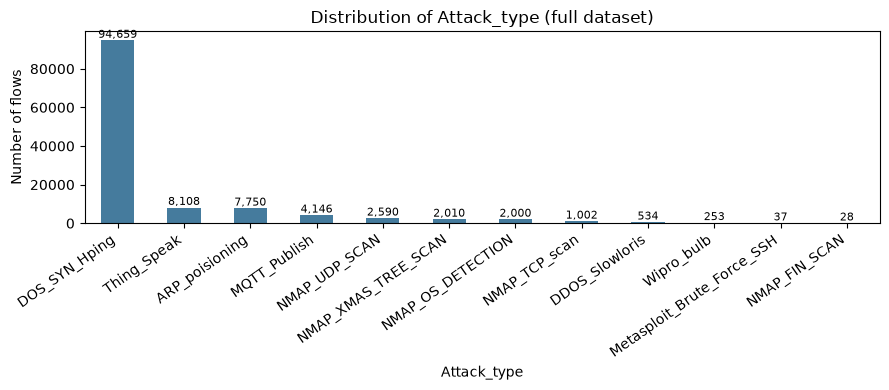

In [18]:
cls = df["Attack_type"].value_counts()
summary = (pd.DataFrame({"flows": cls, "percent": (cls / total * 100).round(2)})
             .join(df.groupby("Attack_type")["label"].max().rename("label")))
display(summary)

plt.figure(figsize=(9, 4))
ax = cls.plot(kind="bar", color="#457b9d")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=8)
plt.title("Distribution of Attack_type (full dataset)")
plt.ylabel("Number of flows")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

**Observation:** one class (a SYN-flood DoS) represents most of the data, while some classes have only a few dozen flows. A multi-class model will need care with these rare classes (class weights, resampling, or grouping them).

## 9. Summary and next steps

- **Data:** 123,117 flows × 85 columns (83 input features + `Attack_type` + `label`). Mostly numeric; only `proto`, `service` and `Attack_type` are text.
- **Quality:** see the missing-value and duplicate counts in section 5.
- **Targets:** binary `label` (≈ 90 % attack) and 12-class `Attack_type`, both strongly imbalanced.
- **Next steps (V1):**
  1. Check duplicates and constant / redundant columns, handle outliers and skewed distributions.
  2. Encode `proto` and `service`; split train/test with stratification.
  3. Train a first baseline (e.g. Random Forest or Logistic Regression) and evaluate it with precision / recall / F1, not accuracy alone.